In [3]:
import os
os.environ["KAGGLE_API_TOKEN"] = "KGAT_64e81a6ee9974ec4fec9d6f857aa62e3"

In [4]:
!pip install -U kaggle
!kaggle kernels output beshoyshohdy/skin-classifier -p model

100% 16.4k/16.4k [00:00<00:00, 389kB/s]

Output file downloaded to model/.virtual_documents/__notebook_source__.ipynb
100% 174M/174M [00:21<00:00, 8.34MB/s]

Output file downloaded to model/best_model.keras
100% 174M/174M [00:22<00:00, 8.08MB/s]

Output file downloaded to model/best_model_final.keras
100% 423M/423M [00:52<00:00, 8.51MB/s]

Output file downloaded to model/best_model_stage_2.keras
100% 460M/460M [00:54<00:00, 8.87MB/s]

Output file downloaded to model/best_model_stage_3.keras
100% 164M/164M [00:22<00:00, 7.76MB/s]

Output file downloaded to model/best_model_stage_4.keras
100% 800/800 [00:00<00:00, 2.73MB/s]

Output file downloaded to model/skin-classifier.log
Kernel log downloaded to model/skin-classifier.log 


In [8]:
!kaggle datasets download -d nischaydnk/isic-2019-jpg-224x224-resized

Dataset URL: https://www.kaggle.com/datasets/nischaydnk/isic-2019-jpg-224x224-resized
License(s): CC0-1.0
100% 355M/355M [00:19<00:00, 19.2MB/s]

unzip:  cannot find or open skin-data.zip, skin-data.zip.zip or skin-data.zip.ZIP.


In [9]:
!unzip -q isic-2019-jpg-224x224-resized.zip -d /content

In [12]:
import pandas as pd

df = pd.read_csv("/content/train-metadata.csv")

In [13]:
df.head()

,Unnamed: 0,isic_id,patient_id,target
0,0,ISIC_0000000,dummy_0,0
1,1,ISIC_0000001,dummy_1,0
2,2,ISIC_0000002,dummy_2,1
3,3,ISIC_0000003,dummy_3,0
4,4,ISIC_0000004,dummy_4,1


In [16]:
df['image_path'] = '/content/train-image/image' + '/' + df['isic_id'] + '.jpg'

In [17]:
import os

print(df['image_path'].iloc[0])
missing = df[~df['image_path'].apply(os.path.exists)]
print("missing:", len(missing), "of", len(df))
print(missing['image_path'].head())

/content/train-image/image/ISIC_0000000.jpg
missing: 0 of 25331
Series([], Name: image_path, dtype: object)


In [18]:
df['target'].value_counts()

,count
target,
0,20809
1,4522


In [19]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["target"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["target"],
    random_state=42
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 17731
Validation: 3800
Test: 3800


In [20]:
import os
import tensorflow as tf

IMG_SIZE = (300, 300)
BATCH_SIZE = 8
AUTOTUNE = tf.data.AUTOTUNE


def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label


def augment(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)

    k = tf.random.uniform([], 0, 4, dtype=tf.int32)
    image = tf.image.rot90(image, k=k)

    image = tf.image.resize_with_crop_or_pad(image, 330, 330)
    image = tf.image.random_crop(
        image, size=[300, 300, 3]
    )

    image = tf.image.random_brightness(image, max_delta=20.0)
    image = tf.image.random_contrast(image, 0.8, 1.2)
    image = tf.image.random_saturation(image, 0.85, 1.15)
    image = tf.clip_by_value(image, 0.0, 255.0)

    return image, label


def create_dataset(dataframe, training=False):
    paths = dataframe["image_path"].to_numpy()
    labels = dataframe["target"].to_numpy().astype("int32")

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        # Shuffle the whole dataset of paths: costs almost nothing
        ds = ds.shuffle(
            len(paths),
            seed=42,
            reshuffle_each_iteration=True
        )

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)

    if training:
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)

    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Datasets created successfully.")

Datasets created successfully.


In [ ]:
to stage 3

# model

# stage 1

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB6

# Create a fresh strategy after restarting
strategy = tf.distribute.MirroredStrategy()
print("Replicas:", strategy.num_replicas_in_sync)

with strategy.scope():
    old_model = tf.keras.models.load_model("/content/best_model_final.keras/best_model_final.keras")

    x = old_model.layers[-2].output
    new_out = layers.Dense(2, activation="softmax", name="out_2")(x)
    base_model = Model(old_model.input, new_out)

    # 2. Truncated backbone
    trunc = tf.keras.Model(base_model.input, cut_layer.output, name="backbone_no_top")

    inputs = layers.Input(shape=(300, 300, 3))
    x = base_model(inputs, training=False)

    x = layers.Dense(512)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.2)(x)

    x = layers.Dense(256)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.2)(x)

    x = layers.Dense(64)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Dropout(0.2)(x)

    outputs = layers.Dense(9, activation="softmax")(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

model.summary()

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(train_df["label"])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"].to_numpy()
)

class_weights = dict(zip(classes, class_weights))

print(class_weights)

In [ ]:

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "best_model.keras",
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=[early_stopping, reduce_lr, checkpoint]
)


# stage 2

In [ ]:
import os
import tensorflow as tf

IMG_SIZE = (300, 300)
BATCH_SIZE = 8
AUTOTUNE = tf.data.AUTOTUNE


def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label


def augment(image, label):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)

    k = tf.random.uniform([], 0, 4, dtype=tf.int32)
    image = tf.image.rot90(image, k=k)

    image = tf.image.resize_with_crop_or_pad(image, 330, 330)
    image = tf.image.random_crop(
        image, size=[300, 300, 3]
    )

    image = tf.image.random_brightness(image, max_delta=20.0)
    image = tf.image.random_contrast(image, 0.8, 1.2)
    image = tf.image.random_saturation(image, 0.85, 1.15)
    image = tf.clip_by_value(image, 0.0, 255.0)

    return image, label


def create_dataset(dataframe, training=False):
    paths = dataframe["image_path"].to_numpy()
    labels = dataframe["label"].to_numpy().astype("int32")

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)

    if training:
        ds = ds.shuffle(
            min(len(paths), 5000),
            seed=42,
            reshuffle_each_iteration=True
        )
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)

    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Datasets created successfully.")

In [ ]:
model.load_weights("best_model.keras")

with strategy.scope():
    for layer in base_model.layers:
        layer.trainable = layer.name.startswith(("block6", "block7", "top_"))
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    model.compile(
        optimizer=tf.keras.optimizers.Adam(5e-5),
        loss=model.loss,          # keep the same loss you used in stage 1
        metrics=["accuracy"],
    )

model.summary()

In [ ]:

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-8,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "best_model_stage_2.keras",
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=100,
    class_weight=class_weights,
    callbacks=[early_stopping, reduce_lr, checkpoint]
)


In [ ]:
class_names = [
    "ak",      # 0
    "akiec",   # 1
    "bcc",     # 2
    "bkl",     # 3
    "df",      # 4
    "mel",     # 5
    "nv",      # 6
    "scc",     # 7
    "vasc"     # 8
]

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score

# Predict probabilities for each class
y_prob = model.predict(test_ds)

# Predicted class indices
y_pred = np.argmax(y_prob, axis=1)

# Extract integer labels from test_ds
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
]).astype(np.int32)

print("y_true shape:", y_true.shape)
print("y_pred shape:", y_pred.shape)

print("\nTest Accuracy:", accuracy_score(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
))


# stage 3

In [ ]:
!kaggle kernels output beshoyshohdy/skin-classifier -p /kaggle/working

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model

strategy = tf.distribute.MirroredStrategy()

with strategy.scope():
    model = tf.keras.models.load_model("best_model_stage_3.keras")
    base_model = [l for l in model.layers if isinstance(l, tf.keras.Model)][0]

    base_model.trainable = True
    for layer in base_model.layers:
        layer.trainable = layer.name.startswith(("block5", "block6", "block7", "top_"))
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    model.compile(
        optimizer=tf.keras.optimizers.Adam(5e-6),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

model.summary()

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(train_df["label"])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["label"].to_numpy()
)

class_weights = dict(zip(classes, class_weights))

print(class_weights)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-8,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "best_model_stage_3.keras",
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=100,
    class_weight=class_weights,
    callbacks=[early_stopping, reduce_lr, checkpoint]
)

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score

# Predict probabilities for each class
y_prob = model.predict(test_ds)

# Predicted class indices
y_pred = np.argmax(y_prob, axis=1)

# Extract integer labels from test_ds
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
]).astype(np.int32)

print("y_true shape:", y_true.shape)
print("y_pred shape:", y_pred.shape)

print("\nTest Accuracy:", accuracy_score(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
))


# stage 4

In [ ]:
!kaggle kernels output beshoyshohdy/skin-classifier -p /kaggle/working

In [22]:
import tensorflow as tf
from tensorflow.keras import layers, Model

strategy = tf.distribute.MirroredStrategy()

with strategy.scope():
    old_model = tf.keras.models.load_model("/content/model/best_model_final.keras")

    x = old_model.layers[-2].output
    new_out = layers.Dense(2, activation="softmax", name="out_8")(x)
    model = Model(old_model.input, new_out)

    # freeze everything except the new last layer
    for l in model.layers[:-1]:
        l.trainable = False

    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

In [23]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(train_df["target"])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["target"].to_numpy()
)

class_weights = dict(zip(classes, class_weights))

print(class_weights)

{np.int64(0): np.float64(0.6086434161746533), np.int64(1): np.float64(2.8011058451816746)}


In [24]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    mode="min",
    factor=0.5,
    patience=1,
    min_lr=1e-6,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "best_model_2_class.keras",
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=2,
    class_weight=class_weights,
    callbacks=[early_stopping, reduce_lr, checkpoint]
)

Epoch 1/2
2217/2217 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step - accuracy: 0.7962 - loss: 0.4239
Epoch 1: val_loss improved from None to 0.30153, saving model to best_model_2_class.keras

Epoch 1: finished saving model to best_model_2_class.keras
2217/2217 ━━━━━━━━━━━━━━━━━━━━ 488s 211ms/step - accuracy: 0.8296 - loss: 0.3766 - val_accuracy: 0.8787 - val_loss: 0.3015 - learning_rate: 0.0010
Epoch 2/2
2217/2217 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step - accuracy: 0.8560 - loss: 0.3418
Epoch 2: val_loss improved from 0.30153 to 0.27741, saving model to best_model_2_class.keras

Epoch 2: finished saving model to best_model_2_class.keras
2217/2217 ━━━━━━━━━━━━━━━━━━━━ 471s 212ms/step - accuracy: 0.8536 - loss: 0.3451 - val_accuracy: 0.8882 - val_loss: 0.2774 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 2.


In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score

# Predict probabilities for each class
y_prob = model.predict(test_ds)

# Predicted class indices
y_pred = np.argmax(y_prob, axis=1)

# Extract integer labels from test_ds
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
]).astype(np.int32)

print("y_true shape:", y_true.shape)
print("y_pred shape:", y_pred.shape)

print("\nTest Accuracy:", accuracy_score(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
))


# final model

In [ ]:
!kaggle kernels output beshoyshohdy/skin-classifier -p /kaggle/working

In [25]:
import tensorflow as tf
from tensorflow.keras import layers, Model

strategy = tf.distribute.MirroredStrategy()

with strategy.scope():
    model = tf.keras.models.load_model("/content/best_model_2_class.keras")
    base_model = [l for l in model.layers if isinstance(l, tf.keras.Model)][0]

    base_model.trainable = True
    for layer in base_model.layers:
        layer.trainable = layer.name.startswith(("top_"))
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False



    model.compile(
        optimizer=tf.keras.optimizers.Adam(5e-4),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )


model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 300, 300, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb6 (Functional)     │ (None, 2304)           │    40,960,143 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ out_8 (Dense)                   │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,291,537 (161.33 MB)

 Trainable params: 1,327,234 (5.06 MB)

 Non-trainable params: 40,964,303 (156.27 MB)

In [27]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(train_df["target"])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["target"].to_numpy()
)

class_weights = dict(zip(classes, class_weights))

print(class_weights)

{np.int64(0): np.float64(0.6086434161746533), np.int64(1): np.float64(2.8011058451816746)}


In [28]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_loss",
    mode="min",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    mode="min",
    factor=0.5,
    patience=1,
    min_lr=1e-6,
    verbose=1
)

checkpoint = ModelCheckpoint(
    "best_model_final_2_class.keras",
    monitor="val_loss",
    mode="min",
    save_best_only=True,
    verbose=1
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    class_weight=class_weights,
    callbacks=[early_stopping, reduce_lr, checkpoint]
)

Epoch 1/30
2217/2217 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step - accuracy: 0.8479 - loss: 0.3639
Epoch 1: val_loss improved from None to 0.24884, saving model to best_model_final_2_class.keras

Epoch 1: finished saving model to best_model_final_2_class.keras
2217/2217 ━━━━━━━━━━━━━━━━━━━━ 493s 215ms/step - accuracy: 0.8500 - loss: 0.3592 - val_accuracy: 0.8984 - val_loss: 0.2488 - learning_rate: 5.0000e-04
Epoch 2/30
2217/2217 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - accuracy: 0.8561 - loss: 0.3409
Epoch 2: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 2: val_loss did not improve from 0.24884
2217/2217 ━━━━━━━━━━━━━━━━━━━━ 462s 208ms/step - accuracy: 0.8580 - loss: 0.3374 - val_accuracy: 0.8608 - val_loss: 0.3009 - learning_rate: 5.0000e-04
Epoch 3/30
2217/2217 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - accuracy: 0.8630 - loss: 0.3209
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.

Epoch 3: val_loss did not improve from 0.24884
2217/2217 ━━━━━━━━

In [32]:
class_names = ['benign', 'malignant']

In [33]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score

# Predict probabilities for each class
y_prob = model.predict(test_ds)

# Predicted class indices
y_pred = np.argmax(y_prob, axis=1)

# Extract integer labels from test_ds
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
]).astype(np.int32)

print("y_true shape:", y_true.shape)
print("y_pred shape:", y_pred.shape)

print("\nTest Accuracy:", accuracy_score(y_true, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
))


475/475 ━━━━━━━━━━━━━━━━━━━━ 83s 175ms/step
y_true shape: (3800,)
y_pred shape: (3800,)

Test Accuracy: 0.8926315789473684

Classification Report:
              precision    recall  f1-score   support

      benign     0.9563    0.9110    0.9331      3122
   malignant     0.6634    0.8083    0.7287       678

    accuracy                         0.8926      3800
   macro avg     0.8099    0.8596    0.8309      3800
weighted avg     0.9040    0.8926    0.8966      3800


Confusion Matrix:
[[2844  278]
 [ 130  548]]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

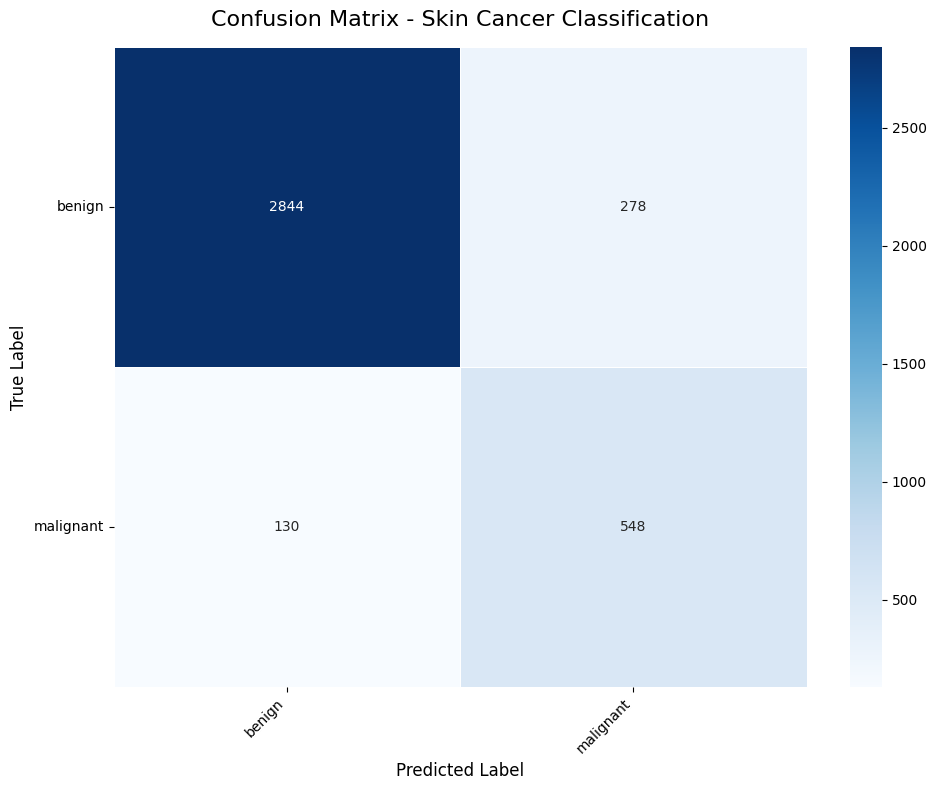

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np


# Calculate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    linewidths=0.5,
    linecolor='white'
)

plt.title('Confusion Matrix - Skin Cancer Classification', fontsize=16, pad=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

# Save the figure
plt.savefig('confusion_matrix_heatmap.png', dpi=300, bbox_inches='tight')

from google.colab import files
files.download('confusion_matrix_heatmap.png')

plt.show()